# 01 - Exploratory Data Analysis

Understanding the Criteo incrementality data *before* modeling: the randomized
design, outcome base rates, whether treatment is statistically effective, and a
covariate-balance check that the randomization actually holds.

> **Data note.** Runs on the committed **synthetic** Criteo-like sample so it executes in seconds and redistributes no proprietary data. For real results use the full dataset (`scripts/download_data.py`, then `--use-raw`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from uplift import config, data
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
df = data.load_sample()
print(f"{len(df):,} rows x {df.shape[1]} columns")

50,000 rows x 16 columns


## Schema & a first look

12 anonymized features `f0`-`f11`, the randomized `treatment`, the `exposure` mediator, and two outcomes (`visit`, the rarer `conversion`).

In [2]:
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,exposure,conversion,visit
0,0.3047,-1.0400,0.7505,0.9406,-1.9510,-1.3022,0.1278,-0.3162,-0.0168,-0.8530,0.8794,0.7778,1,0,0,0
1,0.0660,1.1272,0.4675,-0.8593,0.3688,-0.9589,0.8785,-0.0499,-0.1849,-0.6809,1.2225,-0.1545,1,0,0,1
2,-0.4283,-0.3521,0.5323,0.3654,0.4127,0.4308,2.1416,-0.4064,-0.5122,-0.8138,0.6160,1.1290,0,0,0,0
3,-0.1139,-0.8402,-0.8245,0.6506,0.7433,0.5432,-0.6655,0.2322,0.1167,0.2187,0.8714,0.2236,1,0,0,0
4,0.6789,0.0676,0.2891,0.6313,-1.4572,-0.3197,-0.4704,-0.6389,-0.2751,1.4949,-0.8658,0.9683,1,0,0,0


In [3]:
df.describe().T[['mean','std','min','max']]

,mean,std,min,max
f0,-0.0059,1.0003,-4.2553,3.9926
f1,0.0098,1.0003,-4.2348,4.5851
f2,-0.0006,0.9959,-4.2913,4.9113
f3,0.0036,1.0026,-4.9282,4.6799
f4,0.0026,0.9967,-3.7346,4.6730
f5,0.0072,1.0024,-4.5118,5.0072
f6,-0.0022,1.0025,-4.2570,4.0932
f7,-0.0083,1.0048,-3.8351,4.4617
f8,-0.0004,1.0022,-4.0110,4.0755
f9,-0.0014,1.0053,-4.8156,4.1512


## Treatment assignment & outcome base rates

Criteo is heavily imbalanced (~85% treated) and outcomes are rare - the regime where naive response models waste budget on people who'd convert anyway.

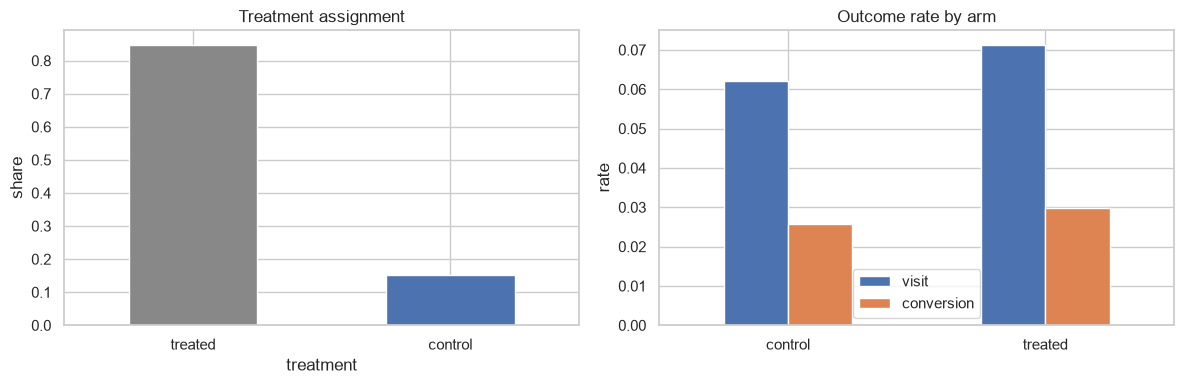

,visit,conversion
control,0.0620,0.0257
treated,0.0714,0.0298


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[config.TREATMENT_COL].value_counts(normalize=True).rename(
    {0: "control", 1: "treated"}).plot.bar(ax=ax[0], color=["#888","#4C72B0"], rot=0)
ax[0].set_title("Treatment assignment"); ax[0].set_ylabel("share")

rates = df.groupby(config.TREATMENT_COL)[config.OUTCOME_COLS].mean()
rates.index = ["control", "treated"]
rates.plot.bar(ax=ax[1], rot=0); ax[1].set_title("Outcome rate by arm"); ax[1].set_ylabel("rate")
plt.tight_layout(); plt.show()
rates

## Is the treatment effective? (two-proportion z-test)

Because assignment is randomized, the difference in outcome rates is an unbiased estimate of the average treatment effect (ATE).

In [5]:
from statsmodels.stats.proportion import proportions_ztest
t = df[config.TREATMENT_COL]
for outcome in config.OUTCOME_COLS:
    y = df[outcome]
    count = np.array([y[t==1].sum(), y[t==0].sum()])
    nobs = np.array([(t==1).sum(), (t==0).sum()])
    stat, p = proportions_ztest(count, nobs)
    ate = y[t==1].mean() - y[t==0].mean()
    print(f"{outcome:11s}  ATE={ate:+.4f}  z={stat:6.1f}  p={p:.2e}")

visit        ATE=+0.0093  z=   2.9  p=3.34e-03
conversion   ATE=+0.0041  z=   2.0  p=4.83e-02


## Did randomization work? Covariate balance

Standardized mean differences (SMD) of each feature between arms. In a valid RCT these sit near 0 - confounding is designed away, which is *why* we can read uplift directly off the arms. |SMD| < 0.1 is the usual rule.

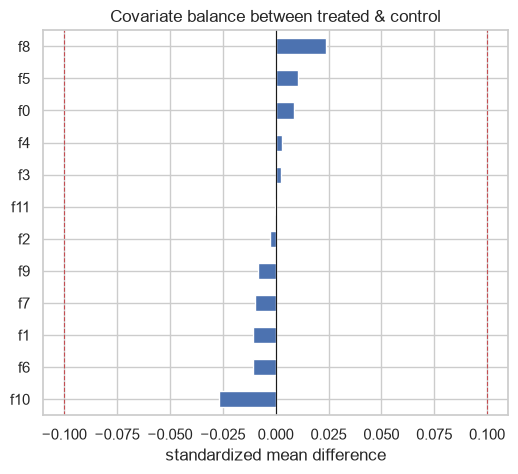

max |SMD| = 0.027


In [6]:
def smd(col):
    a, b = df.loc[t==1, col], df.loc[t==0, col]
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled if pooled else 0.0
bal = pd.Series({f: smd(f) for f in config.FEATURES}).sort_values()
ax = bal.plot.barh(figsize=(6,5))
ax.axvline(0, color="k", lw=0.8); ax.axvline(0.1, color="r", ls="--", lw=0.8)
ax.axvline(-0.1, color="r", ls="--", lw=0.8); ax.set_xlabel("standardized mean difference")
ax.set_title("Covariate balance between treated & control"); plt.show()
print(f"max |SMD| = {bal.abs().max():.3f}")

## Feature correlations

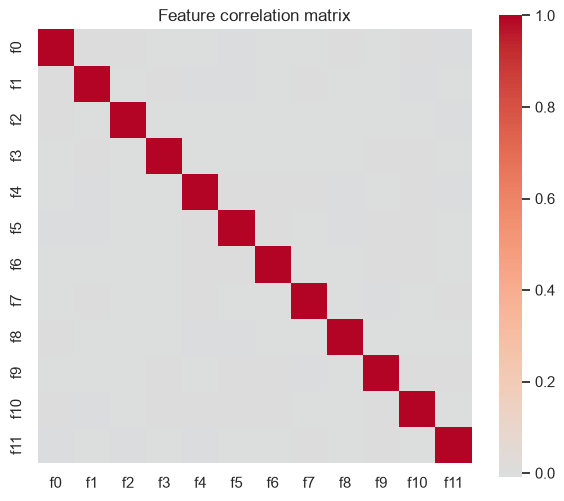

In [7]:
corr = df[config.FEATURES].corr()
plt.figure(figsize=(7,6)); sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Feature correlation matrix"); plt.show()

## The four uplift segments

Every user falls into one of four latent types - the reason ranking by
`P(convert)` is the wrong objective:

| Segment | Treated | Not treated | Target? |
|---|---|---|---|
| **Persuadable** | converts | doesn't |  the whole point |
| **Sure thing** | converts | converts |  wasted spend |
| **Lost cause** | doesn't | doesn't |  wasted spend |
| **Sleeping dog** | doesn't | converts |  actively harmful |

Uplift modeling (next notebooks) finds the persuadables. See
`00_flagship_uplift_analysis.ipynb` for the models and
`02_business_case_profit_curves.ipynb` for the money.